# Fruit & Veg Project — Person 1: Data + EDA
Upload a **zip (or folder) with one sub-folder per fruit/veg**, e.g.

```
my_photos.zip
├── apple/   a1.jpg a2.jpg ...
├── banana/  ...
└── potato/  ...
```
This notebook extracts it, labels each image from its folder name, cleans it, removes duplicates, makes the shared
70/15/15 split, runs EDA, and exports everything your teammates need. Works in Colab or locally.

**Run order:** top to bottom. Only the *Inputs* cell needs editing.

In [1]:
!pip -q install imagehash pillow-heif tqdm 2>&1 | tail -1

[notice] To update, run: pip install --upgrade pip


## 1. Settings & inputs

In [16]:
import os, re, io, json, shutil, zipfile, hashlib, random
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import imagehash
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
try:
    import pillow_heif; pillow_heif.register_heif_opener()   # phone HEIC photos
except Exception: pass

INPUTS = {
    "my_photos": "fruit_photos.zip",
}
# -------------------------------------------

SEED, IMG_SIZE = 42, 224
SPLIT = (0.70, 0.15, 0.15)                      # train / val / test  (agree on this with the team)
CLASSES = ["apple","banana","orange","lemon","tomato","carrot","cucumber","potato"]
ALIASES = {c: [c, c + "s"] for c in CLASSES}
ALIASES["tomato"] += ["tomatoes"]; ALIASES["potato"] += ["potatoes"]
EXCLUDE_TOKENS = {"rotten","rotting","spoiled","stale","juice","pie","sauce","logo","cartoon"}
IMG_EXTS = {".jpg",".jpeg",".png",".bmp",".webp",".heic"}
MIN_SIDE, MAX_SIDE = 64, 512
PHASH_THRESHOLD = 3          # Hamming distance (out of 64 bits) counted as "same image"
MIN_PER_CLASS = 20

DATA = Path("data"); RAW, CLEAN, META, REPORTS = DATA/"raw", DATA/"clean", DATA/"meta", Path("reports")
for p in (RAW, META, REPORTS): p.mkdir(parents=True, exist_ok=True)
random.seed(SEED); np.random.seed(SEED)

try:
    from google.colab import files; IN_COLAB = True
except ImportError:
    IN_COLAB = False

## 2. Upload & extract

In [17]:
def prepare(source, path):
    """Return a folder for this input. Extracts zips; in Colab, prompts an upload if the file is missing."""
    path = Path(path).expanduser()
    if not path.exists() and IN_COLAB:
        print(f"Upload '{path.name}' for source '{source}':")
        up = files.upload()
        name = next(iter(up)); path = Path(name)
    assert path.exists(), f"'{path}' not found. Upload it (Colab: left Files panel) or fix INPUTS."
    if path.is_dir():
        return path
    dest = RAW / source
    if dest.exists(): shutil.rmtree(dest)
    with zipfile.ZipFile(path) as z:
        z.extractall(dest)
    return dest

def match_label(dir_parts, stem=""):
    tok = lambda s: set(t for t in re.split(r"[^a-z]+", s.lower()) if t)
    for part in list(reversed(dir_parts)) + ([stem] if stem else []):
        t = tok(part)
        if t & EXCLUDE_TOKENS: return None
        hits = [c for c in CLASSES if t & set(ALIASES[c])]
        if len(hits) == 1: return hits[0]
        if len(hits) > 1: return None
    return None

folders = {s: prepare(s, p) for s, p in INPUTS.items()}

# find every image, label it from its folder name
rows, unmatched = [], Counter()
for source, root in folders.items():
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in IMG_EXTS or "__MACOSX" in p.parts: continue
        rel = p.relative_to(root)
        lab = match_label(rel.parts[:-1], p.stem)
        if lab is None: unmatched[rel.parts[0] if len(rel.parts) > 1 else "(top level)"] += 1
        rows.append(dict(source=source, label=lab, orig_path=p.as_posix()))
found = pd.DataFrame(rows)
print(f"{len(found)} images found")
display(found.groupby(["label","source"], dropna=False).size().unstack(fill_value=0))
if unmatched:
    print("Folders NOT matched to a class (edit CLASSES/ALIASES above if any of these are really fruit):")
    print(dict(unmatched.most_common(15)))
missing = [c for c in CLASSES if c not in set(found.label.dropna())]
if missing: print("\n⚠️ No images found for:", missing)

80 images found


source,my_photos
label,
apple,11
banana,9
carrot,10
cucumber,10
lemon,10
orange,10
potato,10
tomato,10


## 3. Clean
Unreadable / tiny / unlabeled files are dropped. Phone rotation (EXIF) is fixed, everything is converted to RGB
(transparent PNGs go on white) and downsized to max side 512. Clean copies go to `data/clean/<class>/`.

In [18]:
def load_rgb(path):
    with Image.open(path) as im:
        im.load(); im = ImageOps.exif_transpose(im); ow, oh = im.size
        if im.mode != "RGB":
            rgba = im.convert("RGBA"); bg = Image.new("RGB", rgba.size, (255,255,255))
            bg.paste(rgba, mask=rgba.getchannel("A")); im = bg
        else: im = im.copy()
    return im, ow, oh

if CLEAN.exists(): shutil.rmtree(CLEAN)
recs = []
for r in tqdm(found.to_dict("records"), desc="cleaning"):
    r.update(status="keep", reason="")
    if pd.isna(r["label"]):
        r.update(status="drop", reason="no_label"); recs.append(r); continue
    try: im, ow, oh = load_rgb(r["orig_path"])
    except Exception:
        r.update(status="drop", reason="corrupt_or_unreadable"); recs.append(r); continue
    if min(im.size) < MIN_SIDE:
        r.update(status="drop", reason="too_small"); recs.append(r); continue
    im.thumbnail((MAX_SIDE, MAX_SIDE), Image.LANCZOS)
    arr = np.asarray(im); gray = arr.mean(axis=2)
    uid = hashlib.sha1(arr.tobytes()).hexdigest()[:16]
    out = CLEAN / r["label"] / f"{uid}.jpg"; out.parent.mkdir(parents=True, exist_ok=True)
    if not out.exists(): im.save(out, quality=95)
    r.update(id=uid, clean_path=out.as_posix(), orig_w=ow, orig_h=oh, width=im.width, height=im.height,
             phash=str(imagehash.phash(im)), gray_mean=gray.mean(), gray_std=gray.std(),
             r_mean=arr[...,0].mean(), g_mean=arr[...,1].mean(), b_mean=arr[...,2].mean())
    recs.append(r)
man = pd.DataFrame(recs)
print(man[man.status=="drop"].reason.value_counts().to_string() or "nothing dropped in cleaning")

cleaning:   0%|          | 0/80 [00:00<?, ?it/s]

Series([], )


## 4. Remove duplicates

6 near-duplicate pairs found


,a,b,dist,label_a,label_b
0,fruit_photos.zip/apple/Image_1.jpg,fruit_photos.zip/apple/Image_10.jpg,0,apple,apple
1,fruit_photos.zip/banana/Image_1.jpg,fruit_photos.zip/banana/Image_10.jpg,0,banana,banana
2,fruit_photos.zip/carrot/Image_1.jpg,fruit_photos.zip/carrot/Image_10.jpg,0,carrot,carrot
3,fruit_photos.zip/cucumber/Image_1.jpg,fruit_photos.zip/cucumber/Image_10.jpg,0,cucumber,cucumber
4,fruit_photos.zip/orange/Image_1.png,fruit_photos.zip/orange/Image_10.png,0,orange,orange
5,fruit_photos.zip/tomato/Image_1.jpg,fruit_photos.zip/tomato/Image_10.jpg,0,tomato,tomato


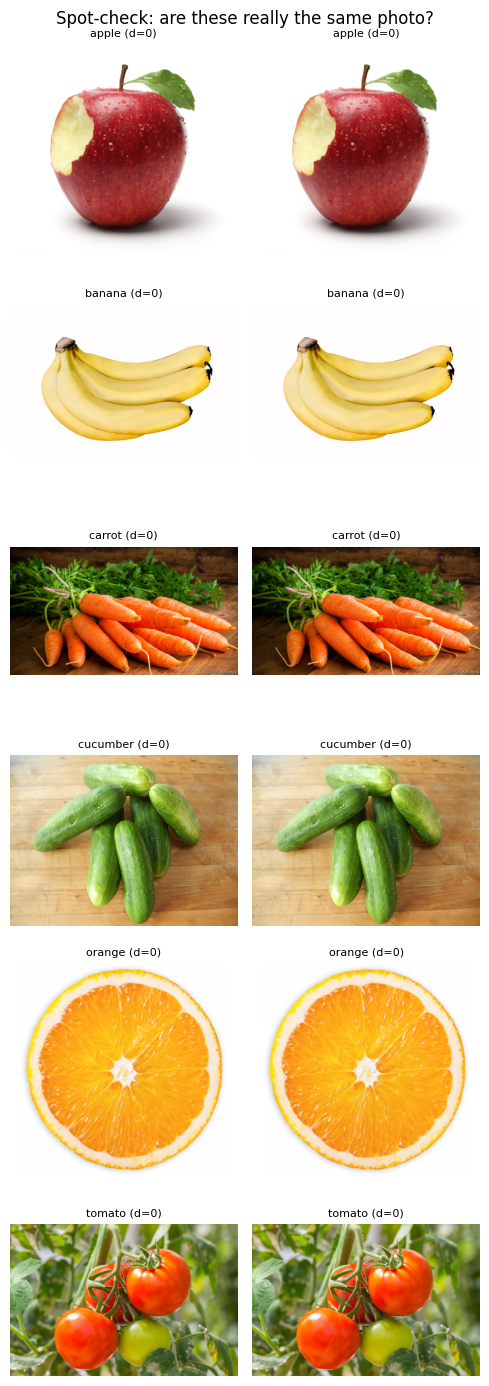


Removed overall:
reason
duplicate    6

Kept per class / source:


source,my_photos,All
label,,
apple,10,10
banana,8,8
carrot,9,9
cucumber,9,9
lemon,10,10
orange,9,9
potato,10,10
tomato,9,9
All,74,74


In [19]:
POP = np.array([bin(i).count("1") for i in range(256)], dtype=np.uint8)
hex_to_u64 = lambda hs: np.array([int(h, 16) for h in hs], dtype=np.uint64)
def popcount_xor(a, b):
    x = np.ascontiguousarray(np.bitwise_xor(a, b)); return POP[x.view(np.uint8).reshape(-1, 8)].sum(axis=1)
def near_pairs(h, thr):
    out = []
    for i in range(len(h)-1):
        d = popcount_xor(h[i+1:], h[i])
        out += [(i, i+1+int(j), int(d[j])) for j in np.nonzero(d <= thr)[0]]
    return out
def min_cross_distance(a, b):
    return 64 if len(a)==0 or len(b)==0 else min(int(popcount_xor(b, x).min()) for x in a)

ok = man.index[man.status=="keep"].to_numpy(); sub = man.loc[ok]
pairs = near_pairs(hex_to_u64(sub.phash), PHASH_THRESHOLD)
parent = list(range(len(sub)))
def find(x):
    while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
    return x
for i, j, _ in pairs: parent[find(i)] = find(j)
clusters = {}
for i in range(len(sub)): clusters.setdefault(find(i), []).append(i)
for members in clusters.values():
    if len(members) < 2: continue
    idx = [ok[m] for m in members]
    if man.loc[idx, "label"].nunique() > 1:
        man.loc[idx, ["status","reason"]] = ["drop","label_conflict"]; continue
    best = (man.loc[idx,"orig_w"] * man.loc[idx,"orig_h"]).idxmax()
    for i in idx:
        if i != best: man.loc[i, ["status","reason"]] = ["drop", "duplicate"]

dups = pd.DataFrame([dict(a=sub.iloc[i].orig_path, b=sub.iloc[j].orig_path, dist=d,
                          label_a=sub.iloc[i].label, label_b=sub.iloc[j].label) for i, j, d in pairs])
print(f"{len(pairs)} near-duplicate pairs found")
if len(dups):
    display(dups)
    show = dups.head(6)
    fig, ax = plt.subplots(len(show), 2, figsize=(5, 2.4*len(show)), squeeze=False)
    for k, r in enumerate(show.itertuples()):
        for c, p in enumerate((r.a, r.b)):
            ax[k, c].imshow(load_rgb(p)[0]); ax[k, c].axis("off"); ax[k, c].set_title(f"{r.label_a if c==0 else r.label_b} (d={r.dist})", fontsize=8)
    plt.suptitle("Spot-check: are these really the same photo?"); plt.tight_layout(); plt.show()

pool = man[man.status=="keep"].copy()
for f in CLEAN.rglob("*.jpg"):                               # delete clean files nobody references
    if f.as_posix() not in set(pool.clean_path): f.unlink()
print("\nRemoved overall:"); print(man[man.status=="drop"].reason.value_counts().to_string())
print("\nKept per class / source:"); display(pd.crosstab(pool.label, pool.source, margins=True))

### Quick manual review
Auto-checks can't catch everything (logos, cartoons, text overlays, plastic fruit). This flags the suspicious ones
and shows a contact sheet per class so you can **delete bad images by id** in the next cell.

Flagged: 0


,id,label,source,flag


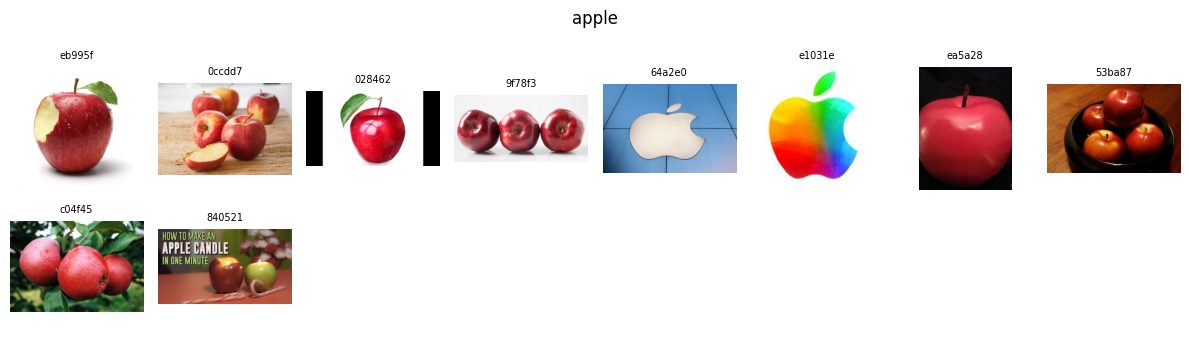

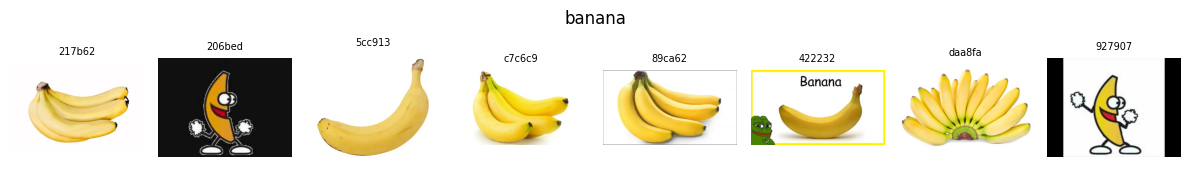

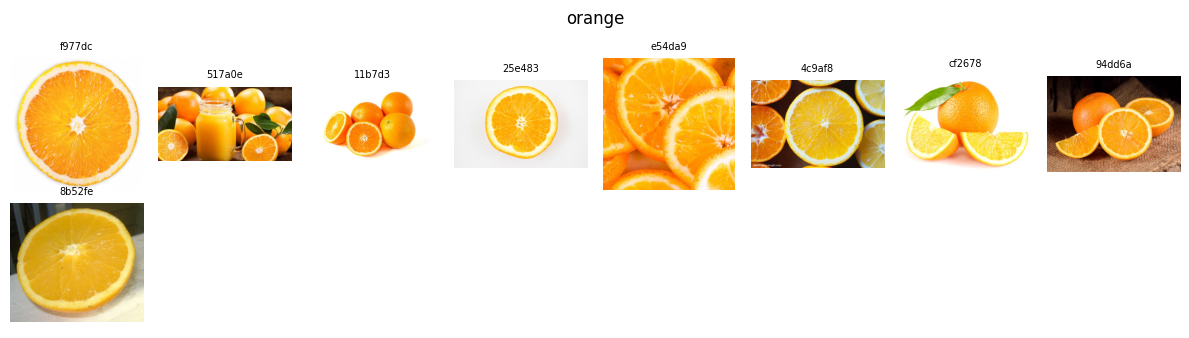

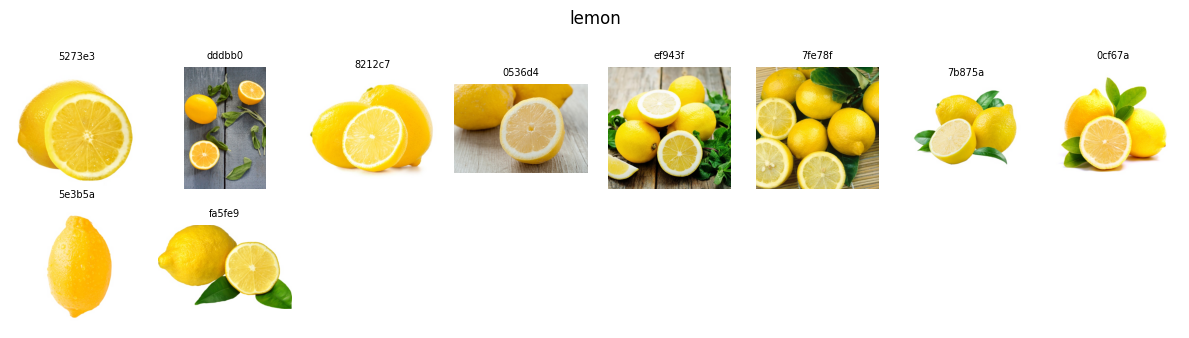

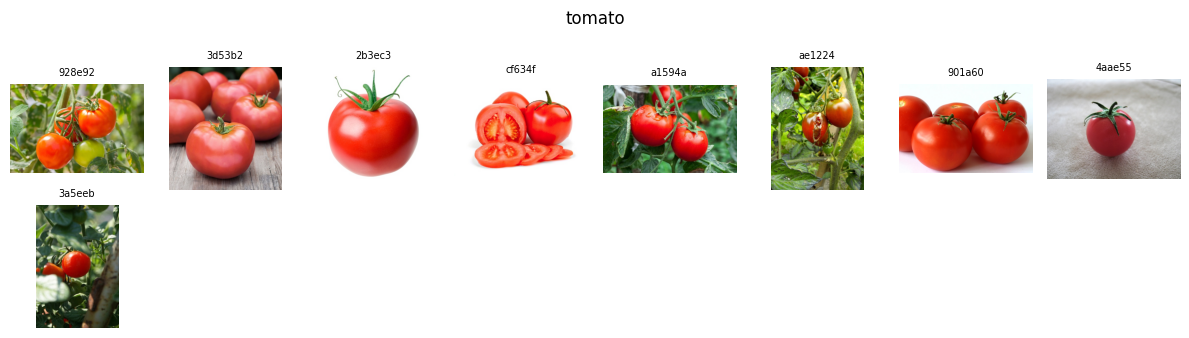

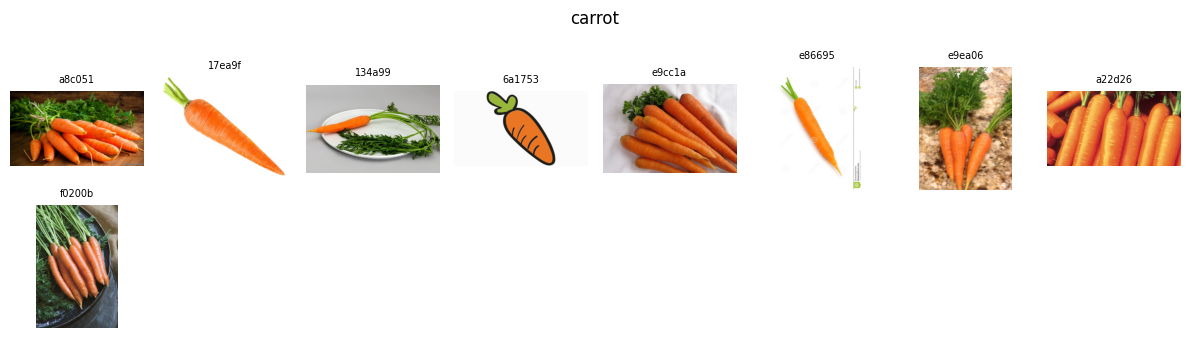

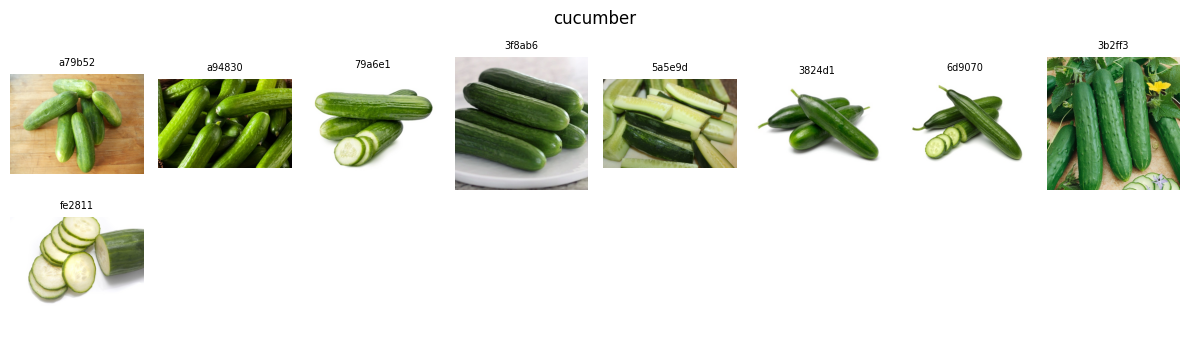

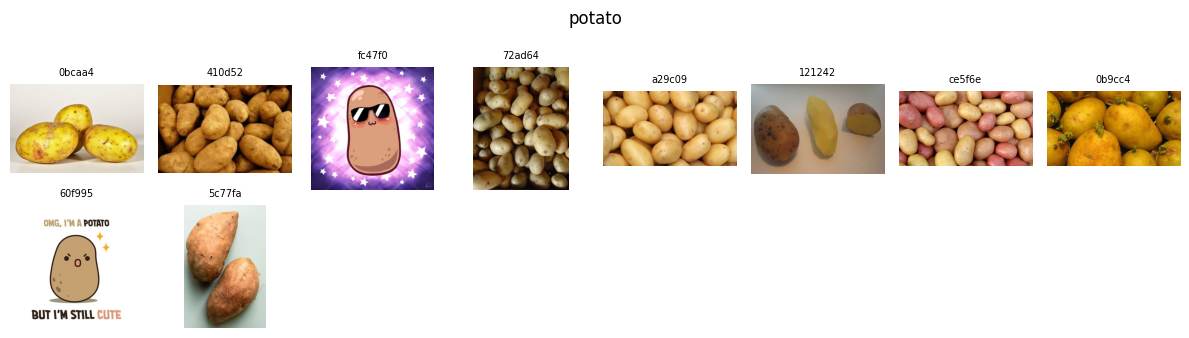

In [20]:
ar = pool.width / pool.height
pool["flag"] = ""
pool.loc[pool.gray_std < 12, "flag"] += "near_blank;"
pool.loc[(ar > 2.5) | (ar < 0.4), "flag"] += "extreme_aspect;"
pool.loc[pool[["width","height"]].min(axis=1) < 128, "flag"] += "small;"
print("Flagged:", (pool.flag != "").sum()); display(pool.loc[pool.flag != "", ["id","label","source","flag"]])

def contact_sheet(label, n=24, cols=8):
    g = pool[pool.label == label].head(n)
    rows_ = int(np.ceil(len(g)/cols)); fig, ax = plt.subplots(rows_, cols, figsize=(cols*1.5, rows_*1.7), squeeze=False)
    for a in ax.ravel(): a.axis("off")
    for a, r in zip(ax.ravel(), g.itertuples()):
        a.imshow(Image.open(r.clean_path)); a.set_title(r.id[:6], fontsize=7)
    plt.suptitle(label); plt.tight_layout(); plt.show()
for c in CLASSES:
    if (pool.label == c).any(): contact_sheet(c)

In [14]:
# Paste ids (the short 6-char titles above work too) of images to remove, then re-run this cell + everything below.
REMOVE_IDS = []   # e.g. ["a1b2c3", "d4e5f6"]
if REMOVE_IDS:
    bad = pool.id.str[:6].isin([i[:6] for i in REMOVE_IDS])
    for f in pool[bad].clean_path: Path(f).unlink(missing_ok=True)
    pool = pool[~bad]; print(f"removed {bad.sum()} images; {len(pool)} left")
pool = pool.drop(columns="flag"); pool.to_csv(META/"pool.csv", index=False); man.to_csv(META/"manifest.csv", index=False)

## 5. Train / val / test split + leakage check

In [15]:
counts = pool.label.value_counts()
small = {c: int(counts.get(c, 0)) for c in CLASSES if counts.get(c, 0) < MIN_PER_CLASS}
assert not small, f"Need at least {MIN_PER_CLASS} images per class. Too few: {small}"

tr, rest = train_test_split(pool, test_size=SPLIT[1]+SPLIT[2], stratify=pool.label, random_state=SEED)
va, te = train_test_split(rest, test_size=SPLIT[2]/(SPLIT[1]+SPLIT[2]), stratify=rest.label, random_state=SEED)
splits = pd.concat([tr.assign(split="train"), va.assign(split="val"), te.assign(split="test")]).reset_index(drop=True)
assert splits.id.is_unique

H = {s: hex_to_u64(g.phash) for s, g in splits.groupby("split")}
for a, b in [("train","val"), ("train","test"), ("val","test")]:
    d = min_cross_distance(H[a], H[b]); assert d > PHASH_THRESHOLD, f"leak between {a} and {b}"
    print(f"min phash distance {a:>5} vs {b:<5}: {d}  OK")

class_to_idx = {c: i for i, c in enumerate(CLASSES)}
splits["label_idx"] = splits.label.map(class_to_idx)
splits[["id","clean_path","label","label_idx","source","split","phash","width","height"]].to_csv(META/"splits.csv", index=False)
json.dump(class_to_idx, open(META/"class_to_idx.json","w"), indent=2)
display(pd.crosstab(splits.label, splits.split, margins=True)[["train","val","test","All"]])

AssertionError: Need at least 20 images per class. Too few: {'apple': 9, 'banana': 8, 'orange': 9, 'lemon': 10, 'tomato': 9, 'carrot': 9, 'cucumber': 9, 'potato': 10}